In [1]:
import keras
import ml_edu.experiment
import ml_edu.results
import numpy as np
import pandas as pd
import plotly.express as px

# The following lines adjust the granularity of reporting.
pd.options.display.max_rows = 10
pd.options.display.float_format = "{:.1f}".format

I0000 00:00:1793714792.222438  193039 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [ ]:
rice_dataset_raw = pd.read_csv(
    "https://download.mlcc.google.com/mledu-datasets/Rice_Cammeo_Osmancik.csv"
)

In [ ]:
rice_dataset: pd.DataFrame = rice_dataset_raw[
    [
        "Area",
        "Perimeter",
        "Major_Axis_Length",
        "Minor_Axis_Length",
        "Eccentricity",
        "Convex_Area",
        "Extent",
        "Class",
    ]
]

rice_dataset.describe()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
count,3810.0,3810.0,3810.0,3810.0,3810.0,3810.0,3810.0
mean,12667.7,454.2,188.8,86.3,0.9,12952.5,0.7
std,1732.4,35.6,17.4,5.7,0.0,1777.0,0.1
min,7551.0,359.1,145.3,59.5,0.8,7723.0,0.5
25%,11370.5,426.1,174.4,82.7,0.9,11626.2,0.6
50%,12421.5,448.9,185.8,86.4,0.9,12706.5,0.6
75%,13950.0,483.7,203.6,90.1,0.9,14284.0,0.7
max,18913.0,548.4,239.0,107.5,0.9,19099.0,0.9


# Explore the dataset

In [ ]:
print(
    f"Length from: {rice_dataset.Major_Axis_Length.min():.1f} to {rice_dataset.Major_Axis_Length.max():.1f}"
)
print(f"Area from {rice_dataset.Area.min():.1f} to {rice_dataset.Area.max():.1f}")
print(
    f"Largest rice grain's perimeter is {(rice_dataset.Perimeter.max() - rice_dataset.Perimeter.mean()) / rice_dataset.Perimeter.std():.1f} stds from mean"
)

Length from: 145.3 to 239.0
Area from 7551.0 to 18913.0
Largest rice grain's perimeter is 2.6 stds from mean


In [ ]:
# Create five 2D plots of the features against each other, color-coded by class.
for x_axis_data, y_axis_data in [
    ("Area", "Eccentricity"),
    ("Convex_Area", "Perimeter"),
    ("Major_Axis_Length", "Minor_Axis_Length"),
    ("Perimeter", "Extent"),
    ("Eccentricity", "Major_Axis_Length"),
]:
    px.scatter(rice_dataset, x=x_axis_data, y=y_axis_data, color="Class").show()

In [ ]:
px.scatter_3d(
    rice_dataset, x="Major_Axis_Length", y="Area", z="Eccentricity", color="Class"
)

# Prepare the dataset

In [ ]:
feature_mean = rice_dataset.mean(numeric_only=True)
feature_std = rice_dataset.std(numeric_only=True)
numerical_features = rice_dataset.select_dtypes("number").columns
normalized_dataset = (rice_dataset[numerical_features] - feature_mean) / feature_std

normalized_dataset["Class"] = rice_dataset["Class"]

normalized_dataset.head()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,1.5,2.0,2.3,-0.2,2.0,1.5,-1.2,Cammeo
1,1.1,1.1,1.0,0.9,0.4,1.2,-0.6,Cammeo
2,1.1,1.3,1.5,0.3,1.2,1.1,0.4,Cammeo
3,0.3,0.1,0.3,0.2,0.2,0.2,-0.3,Cammeo
4,1.2,1.5,1.3,0.5,1.0,1.3,-0.2,Cammeo


In [12]:
keras.utils.set_random_seed(42)

In [ ]:
normalized_dataset["Class_Bool"] = (normalized_dataset["Class"] == "Cammeo").astype(int)
normalized_dataset.sample(10)

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class,Class_Bool
1011,-0.1,0.1,-0.1,0.2,-0.1,-0.0,-1.0,Cammeo,1
3185,-0.1,-0.5,-0.5,0.4,-0.8,-0.2,-0.3,Osmancik,0
3698,0.1,-0.1,-0.4,0.9,-1.1,0.1,-0.2,Osmancik,0
897,0.2,0.5,0.8,-0.5,1.2,0.2,1.5,Cammeo,1
3245,-1.3,-1.3,-0.9,-1.6,0.5,-1.4,-1.1,Osmancik,0
478,0.2,0.2,0.4,-0.0,0.5,0.2,1.7,Cammeo,1
1731,-0.4,-0.8,-0.8,0.3,-1.0,-0.5,-0.4,Osmancik,0
1025,0.6,0.7,0.6,0.3,0.5,0.6,-0.5,Cammeo,1
429,1.2,1.2,1.4,0.6,1.0,1.2,1.8,Cammeo,1
1330,-0.4,-0.0,0.4,-1.3,1.4,-0.5,-0.1,Cammeo,1


In [14]:
number_samples = len(normalized_dataset)
index_80th = round(number_samples * 0.8)
index_90th = index_80th + round(number_samples * 0.1)

shuffled_dataset = normalized_dataset.sample(frac=1, random_state=100)
train_data = shuffled_dataset.iloc[0:index_80th]
validation_data = shuffled_dataset.iloc[index_80th:index_90th]
test_data = shuffled_dataset.iloc[index_90th:]

test_data.head()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class,Class_Bool
2405,-0.4,-0.7,-0.8,0.3,-1.1,-0.4,0.3,Osmancik,0
3062,-0.2,-0.0,0.2,-0.7,0.8,-0.2,1.6,Osmancik,0
1155,1.4,1.2,1.1,1.2,0.3,1.3,0.7,Cammeo,1
660,1.2,1.0,0.8,1.3,-0.0,1.2,-0.6,Cammeo,1
2451,-1.2,-1.2,-1.4,-0.3,-1.5,-1.1,0.1,Osmancik,0


# Create and train the model

In [ ]:
label_columns = ["Class", "Class_Bool"]

train_features = train_data.drop(columns=label_columns)
train_labels = train_data["Class_Bool"].to_numpy()
validation_features = validation_data.drop(columns=label_columns)
validation_labels = validation_data["Class_Bool"].to_numpy()
test_features = test_data.drop(columns=label_columns)
test_labels = test_data["Class_Bool"].to_numpy()

In [ ]:
input_features = [
    "Eccentricity",
    "Major_Axis_Length",
    "Area",
]

In [ ]:
def create_model(
    settings: ml_edu.experiment.ExperimentSettings,
    metrics: list[keras.metrics.Metric],
) -> keras.Model:
    """Create and compile a simple classification model."""
    model_inputs = [
        keras.Input(name=feature, shape=(1,)) for feature in settings.input_features
    ]
    # Use a Concatenate layer to assemble the different inputs into a single
    # tensor which will be given as input to the Dense layer.
    # For example: [input_1[0][0], input_2[0][0]]

    concatenated_inputs = keras.layers.Concatenate()(model_inputs)
    model_output = keras.layers.Dense(
        units=1, name="dense_layer", activation=keras.activations.sigmoid
    )(concatenated_inputs)
    model = keras.Model(inputs=model_inputs, outputs=model_output)
    # Call the compile method to transform the layers into a model that
    # Keras can execute.  Notice that we're using a different loss
    # function for classification than for regression.
    model.compile(
        optimizer=keras.optimizers.RMSprop(settings.learning_rate),
        loss=keras.losses.BinaryCrossentropy(),
        metrics=metrics,
    )
    return model


def train_model(
    experiment_name: str,
    model: keras.Model,
    dataset: pd.DataFrame,
    labels: np.ndarray,
    settings: ml_edu.experiment.ExperimentSettings,
) -> ml_edu.experiment.Experiment:
    """Feed a dataset into the model in order to train it."""

    # The x parameter of keras.Model.fit can be a list of arrays, where
    # each array contains the data for one feature.
    features = {
        feature_name: np.array(dataset[feature_name])
        for feature_name in settings.input_features
    }

    history = model.fit(
        x=features,
        y=labels,
        batch_size=settings.batch_size,
        epochs=settings.number_epochs,
    )

    return ml_edu.experiment.Experiment(
        name=experiment_name,
        settings=settings,
        model=model,
        epochs=history.epoch,
        metrics_history=pd.DataFrame(history.history),
    )

Epoch 1/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7415 - auc: 0.9326 - loss: 0.4367 - precision: 0.6265 - recall: 0.9855  
Epoch 2/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7575 - auc: 0.9388 - loss: 0.4186 - precision: 0.6422 - recall: 0.9832 
Epoch 3/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7730 - auc: 0.9434 - loss: 0.4027 - precision: 0.6584 - recall: 0.9794 
Epoch 4/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7904 - auc: 0.9474 - loss: 0.3880 - precision: 0.6776 - recall: 0.9763 
Epoch 5/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8054 - auc: 0.9506 - loss: 0.3742 - precision: 0.6948 - recall: 0.9756 
Epoch 6/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8127 - auc: 0.9535 - loss: 0.3614 - precision: 0.7039 - recall: 0.9733 
Epoch 7/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8199 - auc: 0.9559 - loss: 0.3494 - precision: 0.7135 - recall: 0.9702 
Epoch 8/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/st

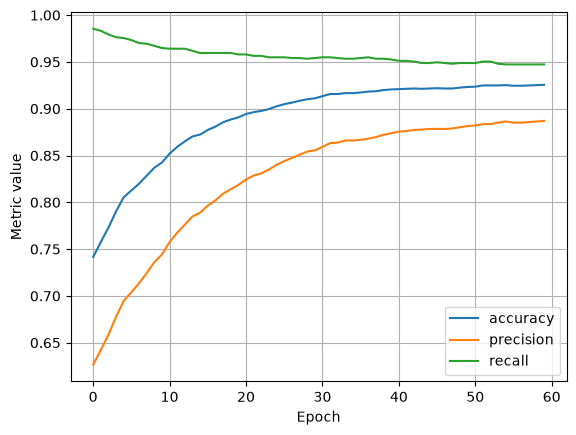

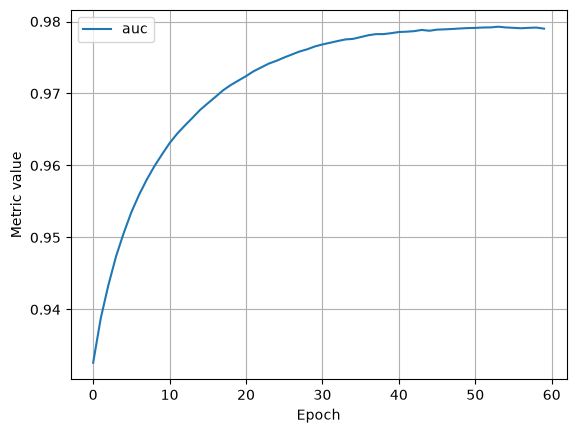

In [ ]:
settings = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.001,
    number_epochs=60,
    batch_size=100,
    classification_threshold=0.35,
    input_features=input_features,
)

metrics = [
    keras.metrics.BinaryAccuracy(
        name="accuracy", threshold=settings.classification_threshold
    ),
    keras.metrics.Precision(
        name="precision", thresholds=settings.classification_threshold
    ),
    keras.metrics.Recall(name="recall", thresholds=settings.classification_threshold),
    keras.metrics.AUC(num_thresholds=100, name="auc"),
]

# Establish the model's topography.
model = create_model(settings, metrics)

# Train the model on the training set.
experiment = train_model("baseline", model, train_features, train_labels, settings)

# Plot metrics vs. epochs
ml_edu.results.plot_experiment_metrics(experiment, ["accuracy", "precision", "recall"])
ml_edu.results.plot_experiment_metrics(experiment, ["auc"])

In [ ]:
def compare_train_validation(
    experiment: ml_edu.experiment.Experiment, validation_metrics: dict[str, float]
):
    print("Comparing metrics between train and validation:")
    for metric, validation_value in validation_metrics.items():
        print("------")
        print(f"Train {metric}: {experiment.get_final_metric_value(metric):.4f}")
        print(f"Validation {metric}:  {validation_value:.4f}")


# Evaluate validation metrics
validation_metrics = experiment.evaluate(validation_features, validation_labels)
compare_train_validation(experiment, validation_metrics)

Comparing metrics between train and validation:
------
Train accuracy: 0.9255
Validation accuracy:  0.8976
------
Train auc: 0.9790
Validation auc:  0.9720
------
Train loss: 0.1826
Validation loss:  0.2150
------
Train precision: 0.8870
Validation precision:  0.8495
------
Train recall: 0.9473
Validation recall:  0.9349


Epoch 1/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5764 - auc: 0.5948 - loss: 0.7458 - precision: 0.5061 - recall: 0.5737
Epoch 2/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6280 - auc: 0.6639 - loss: 0.6792 - precision: 0.5594 - recall: 0.6295 
Epoch 3/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6726 - auc: 0.7252 - loss: 0.6215 - precision: 0.6073 - recall: 0.6723 
Epoch 4/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7201 - auc: 0.7806 - loss: 0.5690 - precision: 0.6566 - recall: 0.7303 
Epoch 5/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7572 - auc: 0.8277 - loss: 0.5212 - precision: 0.6942 - recall: 0.7769 
Epoch 6/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7858 - auc: 0.8669 - loss: 0.4782 - precision: 0.7262 - recall: 0.8044 
Epoch 7/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8146 - auc: 0.8973 - loss: 0.4396 - precision: 0.7580 - recall: 0.8350 
Epoch 8/60
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/ste

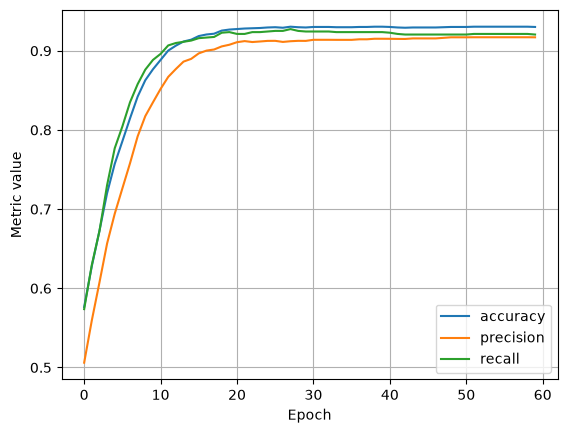

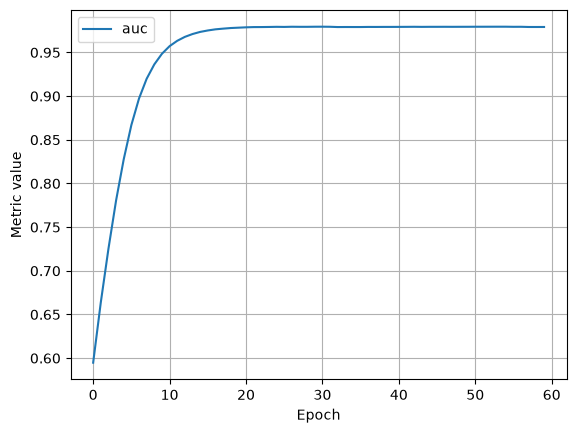

In [ ]:
all_input_features = [
    "Area",
    "Perimeter",
    "Major_Axis_Length",
    "Minor_Axis_Length",
    "Eccentricity",
    "Convex_Area",
    "Extent",
]

settings_all_features = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.001,
    number_epochs=60,
    batch_size=100,
    classification_threshold=0.5,
    input_features=all_input_features,
)

# Modify the following definition of METRICS to generate
# not only accuracy and precision, but also recall:
metrics = [
    keras.metrics.BinaryAccuracy(
        name="accuracy",
        threshold=settings_all_features.classification_threshold,
    ),
    keras.metrics.Precision(
        name="precision",
        thresholds=settings_all_features.classification_threshold,
    ),
    keras.metrics.Recall(
        name="recall", thresholds=settings_all_features.classification_threshold
    ),
    keras.metrics.AUC(num_thresholds=100, name="auc"),
]

# Establish the model's topography.
model_all_features = create_model(settings_all_features, metrics)

# Train the model on the training set.
experiment_all_features = train_model(
    "all features",
    model_all_features,
    train_features,
    train_labels,
    settings_all_features,
)

# Plot metrics vs. epochs
ml_edu.results.plot_experiment_metrics(
    experiment_all_features, ["accuracy", "precision", "recall"]
)
ml_edu.results.plot_experiment_metrics(experiment_all_features, ["auc"])

In [24]:
validation_metrics_all_features = experiment_all_features.evaluate(
    validation_features,
    validation_labels,
)
compare_train_validation(experiment_all_features, validation_metrics_all_features)

Comparing metrics between train and validation:
------
Train accuracy: 0.9301
Validation accuracy:  0.9108
------
Train auc: 0.9792
Validation auc:  0.9711
------
Train loss: 0.1800
Validation loss:  0.2160
------
Train precision: 0.9170
Validation precision:  0.8902
------
Train recall: 0.9206
Validation recall:  0.9112


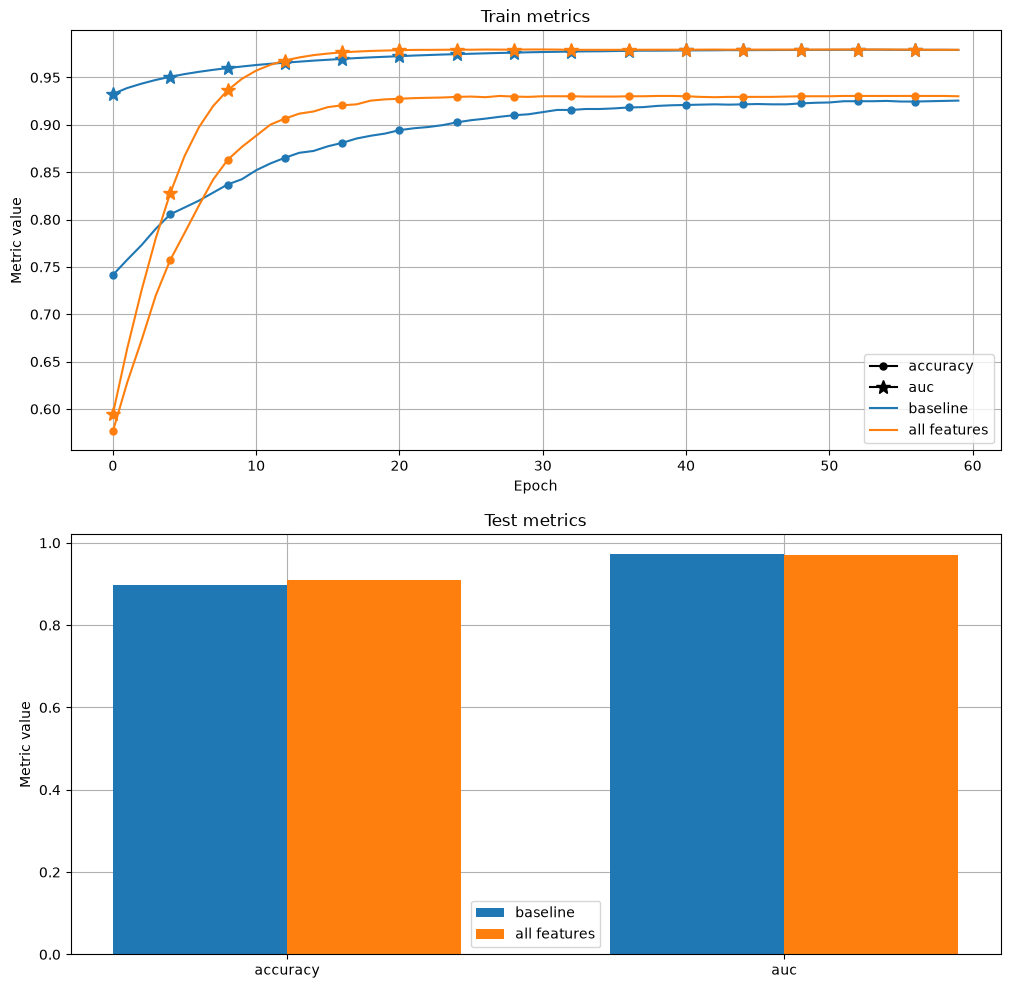

In [ ]:
ml_edu.results.compare_experiment(
    [experiment, experiment_all_features],
    ["accuracy", "auc"],
    validation_features,
    validation_labels,
)

In [ ]:
test_metrics_all_features = experiment_all_features.evaluate(
    test_features,
    test_labels,
)
for metric, test_value in test_metrics_all_features.items():
    print(f"Test {metric}:  {test_value:.4f}")

Test accuracy:  0.9239
Test auc:  0.9761
Test loss:  0.1895
Test precision:  0.9128
Test recall:  0.8947
